### Assignment 1 (4 scores):

- Use Numpy only to construct the Logistic Regression model.
- Train and evaluating (precision, recall, f1) the Logistic Regression model using the Gradient Descent approach **to classify 0 and 1 digit images** on the [MNIST](https://github.com/cvdfoundation/mnist?tab=readme-ov-file) dataset.
- Visualize the loss function of the training process.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split

mnist = fetch_openml('mnist_784', version=1, parser='auto')
X = mnist.data.to_numpy() if hasattr(mnist.data, 'to_numpy') else np.array(mnist.data)
y = mnist.target.to_numpy() if hasattr(mnist.target, 'to_numpy') else np.array(mnist.target)

In [3]:
y = y.astype(int)
X = X.astype(int)

In [4]:
mask = (y == 0) | (y == 1)
X = X[mask]
y = y[mask]

In [5]:
X = X / 255.0

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [ ]:
class LogisticRegressionNumPy:
    def __init__(self, learning_rate=0.1, epochs=500):
        self.lr = learning_rate
        self.epochs = epochs
        self.weights = None
        self.bias = None
        self.loss_history = []

    def _sigmoid(self, z):
        z = np.clip(z, -500, 500)
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.weights = np.zeros(n_features)
        self.bias = 0.0

        for epoch in range(self.epochs):
            linear_model = np.dot(X, self.weights) + self.bias
            y_predicted = self._sigmoid(linear_model)

            epsilon = 1e-15
            y_predicted_clipped = np.clip(y_predicted, epsilon, 1 - epsilon)
            loss = -np.mean(y * np.log(y_predicted_clipped) + (1 - y) * np.log(1 - y_predicted_clipped))
            self.loss_history.append(loss)

            dw = (1 / n_samples) * np.dot(X.T, (y_predicted - y))
            db = (1 / n_samples) * np.sum(y_predicted - y)

            self.weights -= self.lr * dw
            self.bias -= self.lr * db

            if (epoch + 1) % 100 == 0 or epoch == 0:
                print(f"Epoch {epoch+1}/{self.epochs} - Loss: {loss:.4f}")

    def predict_proba(self, X):
        linear_model = np.dot(X, self.weights) + self.bias
        return self._sigmoid(linear_model)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

In [36]:
model = LogisticRegressionNumPy(learning_rate=0.1, epochs=700)
model.fit(X_train, y_train)

Epoch 1/700 - Loss: 0.6931
Epoch 100/700 - Loss: 0.0216
Epoch 200/700 - Loss: 0.0141
Epoch 300/700 - Loss: 0.0112
Epoch 400/700 - Loss: 0.0096
Epoch 500/700 - Loss: 0.0086
Epoch 600/700 - Loss: 0.0079
Epoch 700/700 - Loss: 0.0073


In [18]:
def evaluate_metrics(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    tn = np.sum((y_true == 0) & (y_pred == 0))

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
    
    return precision, recall, f1, tp, fp, fn, tn

y_pred = model.predict(X_test)
precision, recall, f1, tp, fp, fn, tn = evaluate_metrics(y_test, y_pred)

In [19]:
y_pred = model.predict(X_test)
precision, recall, f1, tp, fp, fn, tn = evaluate_metrics(y_test, y_pred)

In [21]:
print(f"Precision: {precision:.5f}")
print(f"Recall: {recall:.5f}")
print(f"F1-Score: {f1:.5f}")
print(f"Confusion Matrix: TP={tp}, FP={fp}, FN={fn}, TN={tn}")


Precision: 0.99746
Recall: 0.99683
F1-Score: 0.99714
Confusion Matrix: TP=1570, FP=4, FN=5, TN=1377


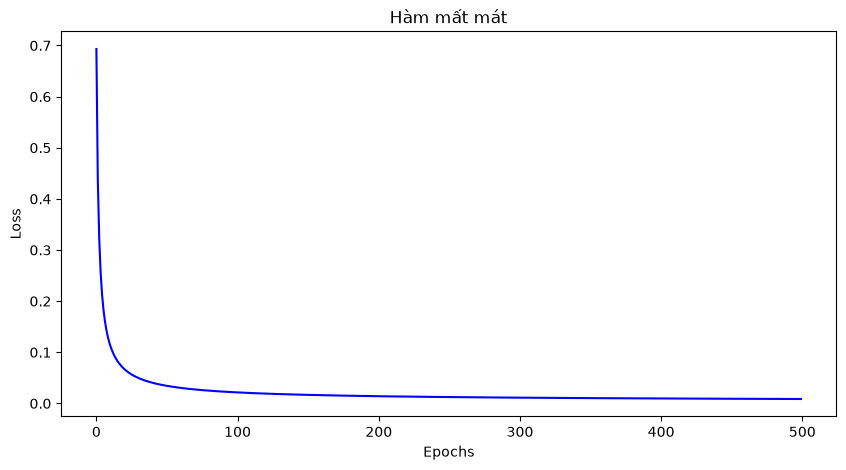

In [22]:
plt.figure(figsize=(10, 5))
plt.plot(model.loss_history, color='blue')
plt.title('Hàm mất mát')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.show()

### Assignment 2 (4 scores):

- Use Numpy only to construct the Softmax Regression model.
- Train and evaluating (precision, recall, f1) the Softmax Regression model using the Gradient Descent approach **to classify 10 digit images** on the [MNIST](https://github.com/cvdfoundation/mnist?tab=readme-ov-file) dataset.
- Visualize the loss function of the training process.

In [30]:
X_train_1, X_test_1, y_train_1, y_test_1 = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [ ]:
class SoftmaxRegressionNumPy:
    def __init__(self, learning_rate=0.1, epochs=300):
        self.lr = learning_rate
        self.epochs = epochs
        self.W = None
        self.b = None
        self.loss_history = []

    def _softmax(self, z):
        exp_z = np.exp(z - np.max(z, axis=1, keepdims=True))
        return exp_z / np.sum(exp_z, axis=1, keepdims=True)

    def _to_one_hot(self, y, num_classes):
        one_hot = np.zeros((y.size, num_classes))
        one_hot[np.arange(y.size), y] = 1
        return one_hot

    def fit(self, X, y):
        n_samples, n_features = X.shape
        num_classes = len(np.unique(y))
        
        # Khởi tạo trọng số W và bias b
        self.W = np.zeros((n_features, num_classes))
        self.b = np.zeros((1, num_classes))
        
        Y_one_hot = self._to_one_hot(y, num_classes)

        for epoch in range(self.epochs):
            scores = np.dot(X, self.W) + self.b
            probs = self._softmax(scores)

            epsilon = 1e-15
            probs_clipped = np.clip(probs, epsilon, 1 - epsilon)
            loss = -np.mean(np.sum(Y_one_hot * np.log(probs_clipped), axis=1))
            self.loss_history.append(loss)

            dw = (1 / n_samples) * np.dot(X.T, (probs - Y_one_hot))
            db = (1 / n_samples) * np.sum(probs - Y_one_hot, axis=0, keepdims=True)

            self.W -= self.lr * dw
            self.b -= self.lr * db

            if (epoch + 1) % 50 == 0 or epoch == 0:
                print(f"Epoch {epoch+1}/{self.epochs} - Loss: {loss:.4f}")

    def predict_proba(self, X):
        scores = np.dot(X, self.W) + self.b
        return self._softmax(scores)

    def predict(self, X):
        probs = self.predict_proba(X)
        return np.argmax(probs, axis=1)

In [34]:
softmax_model = SoftmaxRegressionNumPy(learning_rate=0.1, epochs=300)
softmax_model.fit(X_train_1, y_train_1)

Epoch 1/300 - Loss: 0.6931
Epoch 50/300 - Loss: 0.0215
Epoch 100/300 - Loss: 0.0140
Epoch 150/300 - Loss: 0.0112
Epoch 200/300 - Loss: 0.0096
Epoch 250/300 - Loss: 0.0086
Epoch 300/300 - Loss: 0.0079


In [53]:
def evaluate_multiclass_metrics(y_true, y_pred, num_classes=10):
    cm = np.zeros((num_classes, num_classes), dtype=int)
    for t, p in zip(y_true, y_pred):
        cm[t, p] += 1

    precisions, recalls, f1s = [], [], []
    for c in range(num_classes):
        tp = cm[c, c]
        fp = np.sum(cm[:, c]) - tp
        fn = np.sum(cm[c, :]) - tp

        p = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        r = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        f1 = 2 * (p * r) / (p + r) if (p + r) > 0 else 0.0

        precisions.append(p)
        recalls.append(r)
        f1s.append(f1)

    return np.mean(precisions), np.mean(recalls), np.mean(f1s), cm

In [54]:
y_pred_1 = softmax_model.predict(X_test_1)
macro_p, macro_r, macro_f1, conf_matrix = evaluate_multiclass_metrics(y_test_1, y_pred_1, num_classes=10)

In [55]:
print(f"Macro Precision: {macro_p:.4f}")
print(f"Macro Recall: {macro_r:.4f}")
print(f"Macro F1-Score: {macro_f1:.4f}")

Macro Precision: 0.1994
Macro Recall: 0.1995
Macro F1-Score: 0.1995


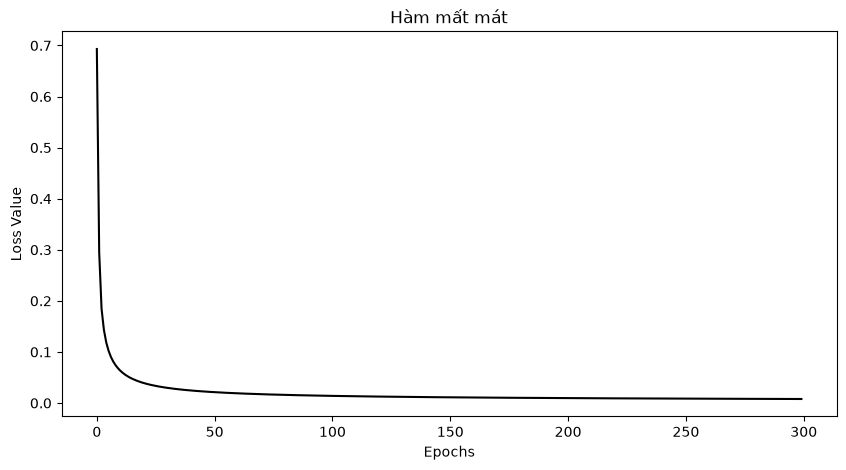

In [56]:
plt.figure(figsize=(10, 5))
plt.plot(softmax_model.loss_history, color='black')
plt.title('Hàm mất mát')
plt.xlabel('Epochs')
plt.ylabel('Loss Value')
plt.show()

### Assignment 3 (2 scores):

- Use a Machine Learning library (Scikit Learn or Skorch) to implement and evaluate the Logistic Regression on the [MNIST](https://github.com/cvdfoundation/mnist?tab=readme-ov-file) dataset.
- Use a Machine Learning library (Scikit Learn or Skorch) to implement and evaluate the Softmax Regression on the [MNIST](https://github.com/cvdfoundation/mnist?tab=readme-ov-file) dataset.

In [57]:
from sklearn.linear_model import LogisticRegression as SklearnLR
from sklearn.metrics import precision_recall_fscore_support

In [58]:
mask_2 = (y == 0) | (y == 1)
X_2 = X[mask_2]
y_2 = y[mask_2]

X_train_2, X_test_2, y_train_2, y_test_2 = train_test_split(
    X_2, y_2, test_size=0.2, random_state=42, stratify=y_2
)

In [59]:
sk_lr = SklearnLR(max_iter=500, random_state=42)
sk_lr.fit(X_train_2, y_train_2)
y_pred_2 = sk_lr.predict(X_test_2)

In [ ]:
p_2, r_2, f1_2, _ = precision_recall_fscore_support(y_test_2, y_pred_2, average='binary')
print(f"Precision: {p_2:.4f}")
print(f"Recall: {r_2:.4f}")
print(f"F1-Score: {f1_2:.4f}")

Precision: 0.9994
Recall: 0.9975
F1-Score: 0.9984



In [62]:
sk_softmax = SklearnLR(solver='lbfgs', max_iter=500, random_state=42)
sk_softmax.fit(X_train_1, y_train_1)
y_pred_full = sk_softmax.predict(X_test_1)

# Đánh giá đa lớp dùng trung bình Macro (Macro Average)
p_macro, r_macro, f1_macro, _ = precision_recall_fscore_support(y_test_1, y_pred_1, average='macro')
print(f"Macro Precision : {p_macro:.4f}")
print(f"Macro Recall    : {r_macro if 'r_macro' in locals() else r_macro:.4f}") 
print(f"Macro F1-Score  : {f1_macro:.4f}")

Macro Precision : 0.9972
Macro Recall    : 0.9973
Macro F1-Score  : 0.9973
